# Shear versus ellipticity gradient

In [5]:
import numpy as np

from matplotlib import pyplot as plt
# Use TeX
from matplotlib import rc
rc('text', usetex=True)
rc('font', family='serif')
rc('font', size=18)

## 1. SIS + shear

Here I aim to show that an SIS + shear is equivalent to an isothermal potential with ellipticity gradient.

In [6]:
from lenstronomy.LensModel.lens_model import LensModel

In [17]:
# Model 1 = SIS + shear

lens_model_SIS_shear = LensModel(lens_model_list=['SIS', 'SHEAR'])
kwargs_SIS = {'center_x': 0.0, 'center_y': 0.0, 'theta_E': 1.0}
kwargs_SHEAR = {'ra_0': 0.0, 'dec_0': 0.0, 'gamma1':0.03, 'gamma2': -0.02}
kwargs_lens_SIS_shear = [kwargs_SIS, kwargs_SHEAR]


# Model 2 = GEP

GEP_configuration = {
    'parameterization': 'rectangular',
    'ellipticity_model': 'linear',
    'pointing_angle_model': None,
    'position_model': 'linear',
    'radial_potential': 'power_law'}

lens_model_GEP = LensModel(lens_model_list=['GEP'], profile_kwargs_list=[GEP_configuration])
kwargs_GEP = {
    'center_x': 0.0, 'center_y': 0.0,
    'theta_E': kwargs_SIS['theta_E'],
    'gamma': 2.0,
    'e1_0': 0.0, 'e2_0': 0.0,
    'e1_1': - kwargs_SHEAR['gamma1']/kwargs_SIS['theta_E'],
    'e2_1': - kwargs_SHEAR['gamma2']/kwargs_SIS['theta_E'],
    #'e1_1': 0.0, 'e2_1': 0.0,
    'v_x': 0.0, 'v_y': 0.0
}
kwargs_lens_GEP = [kwargs_GEP]

### Potential

In [18]:
x = np.linspace(-1, 1, 100) * 2 * kwargs_SIS['theta_E']
y = np.linspace(-1, 1, 100) * 2 * kwargs_SIS['theta_E']
X, Y = np.meshgrid(x, y)

psi_SIS_shear = lens_model_SIS_shear.potential(X, Y, kwargs_lens_SIS_shear)
psi_GEP = lens_model_GEP.potential(X, Y, kwargs_lens_GEP)
dpsi = psi_GEP - psi_SIS_shear

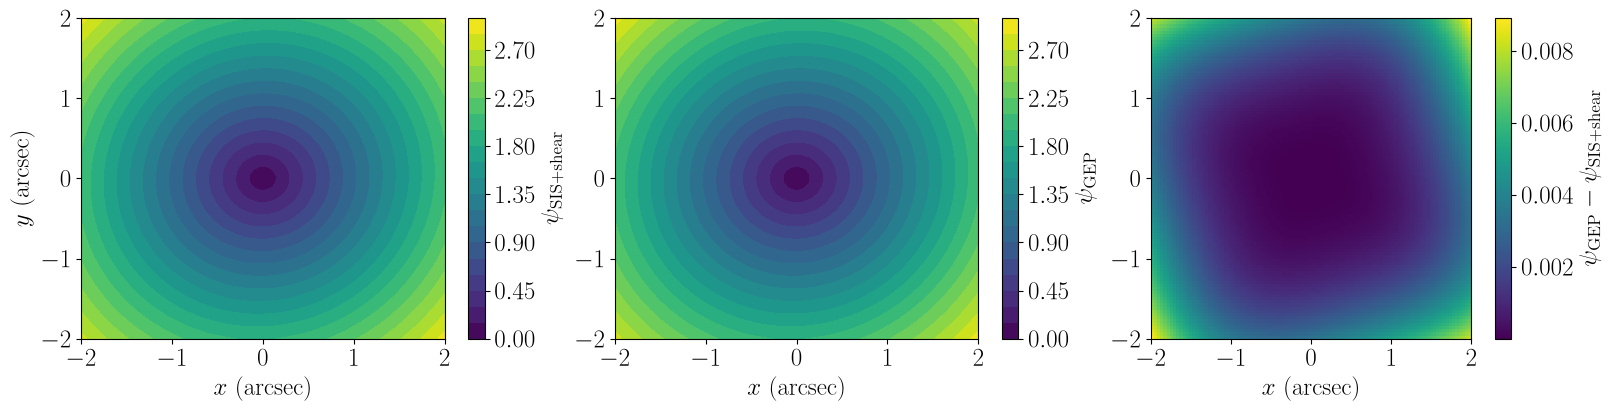

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")

psis = [psi_SIS_shear, psi_GEP, dpsi]
labels = [r'$\psi_{\rm SIS+shear}$', r'$\psi_{\rm GEP}$', r'$\psi_{\rm GEP} - \psi_{\rm SIS+shear}$']

ax = axes[0]
contours = ax.contourf(X, Y, psi_SIS_shear, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\psi_{\rm SIS+shear}$')

ax = axes[1]
contours = ax.contourf(X, Y, psi_GEP, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\psi_{\rm GEP}$')

ax = axes[2]
im = ax.imshow(dpsi, extent=(-2*kwargs_SIS['theta_E'], 2*kwargs_SIS['theta_E'],
                             -2*kwargs_SIS['theta_E'], 2*kwargs_SIS['theta_E']))
fig.colorbar(im, ax=ax, label=r'$\psi_{\rm GEP} - \psi_{\rm SIS+shear}$')

for i in range(3):
    axes[i].set_xlabel(r"$x$ (arcsec)")
axes[0].set_ylabel(r"$y$ (arcsec)")
        
plt.show();

### Displacement angle

In [25]:
alpha_SIS_shear = lens_model_SIS_shear.alpha(X, Y, kwargs_lens_SIS_shear)
alpha_GEP = lens_model_GEP.alpha(X, Y, kwargs_lens_GEP)

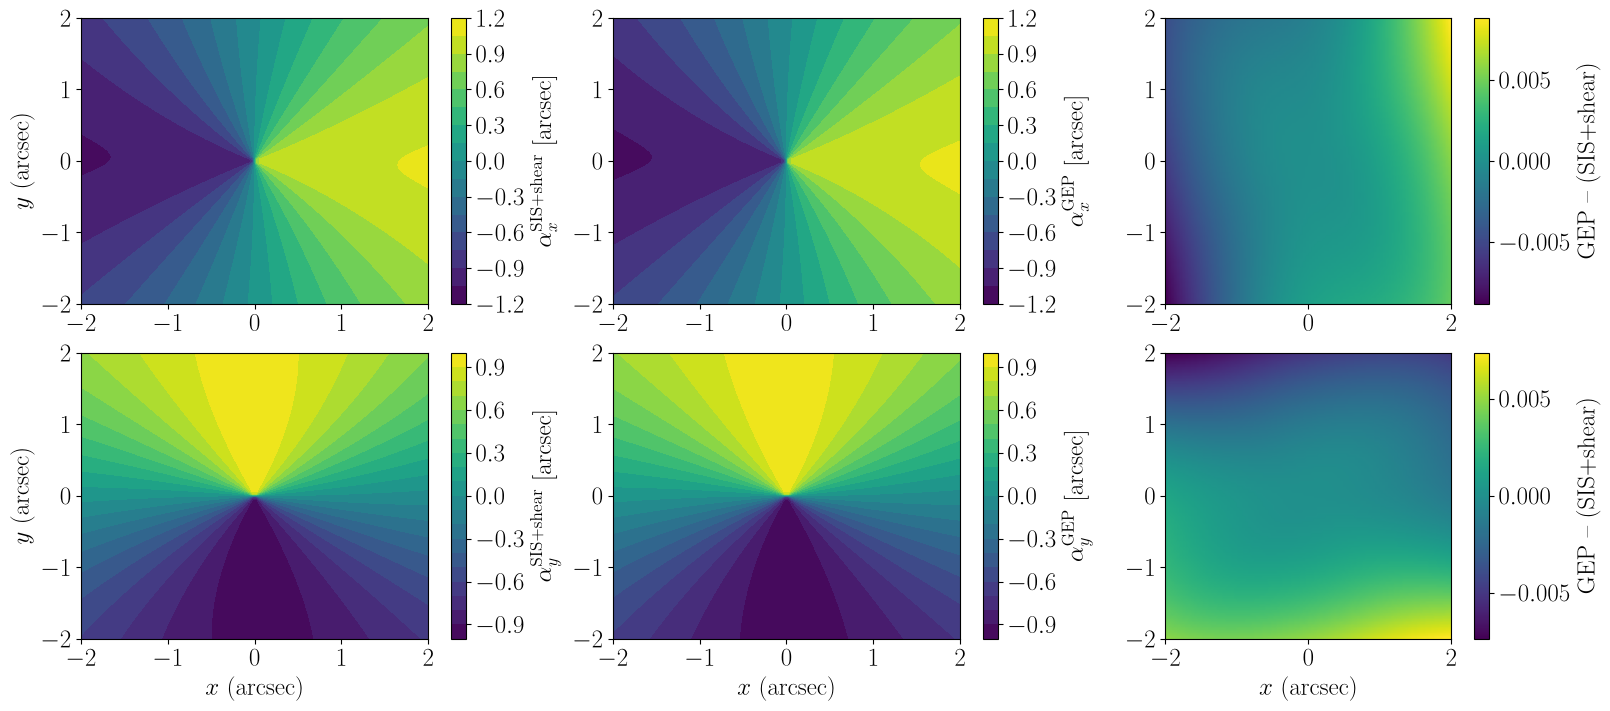

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 3.5*2), layout="constrained")

labels = [[r'$\alpha_x^{\rm SIS+shear}$ [arcsec]', r'$\alpha_x^{\rm GEP}$ [arcsec]', r'GEP -- (SIS+shear)'],
          [r'$\alpha_y^{\rm SIS+shear}$ [arcsec]', r'$\alpha_y^{\rm GEP}$ [arcsec]', r'GEP -- (SIS+shear)']]

for i, alpha_i_GEP in enumerate(alpha_GEP):

    alpha_i_SIS_shear = alpha_SIS_shear[i]
    dalpha_i = alpha_i_GEP -  alpha_i_SIS_shear

    ax = axes[i, 0]
    contours = ax.contourf(X, Y, alpha_i_SIS_shear, levels=20)
    fig.colorbar(contours, ax=ax, label=labels[i][0])

    ax = axes[i, 1]
    contours = ax.contourf(X, Y, alpha_i_GEP, levels=20)
    fig.colorbar(contours, ax=ax, label=labels[i][1])

    ax = axes[i, 2]
    im = ax.imshow(dalpha_i, extent=(-2*kwargs_SIS['theta_E'], 2*kwargs_SIS['theta_E'],
                             -2*kwargs_SIS['theta_E'], 2*kwargs_SIS['theta_E']))
    fig.colorbar(im, ax=ax, label=labels[i][2])

for i in range(2):
    axes[i, 0].set_ylabel(r"$y$ (arcsec)")
    
for j in range(3):
    axes[1, j].set_xlabel(r"$x$ (arcsec)")
        

plt.show();